In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
# Load mtcars directly from the online R dataset
df = sm.datasets.get_rdataset("mtcars", "datasets", cache=True).data
print("DATASET SHAPE:", df.shape)
print("\nFIRST SIX ROWS:")
print(df.head(6).to_string())
# Select the six variables specified in the assignment
cols = ["mpg", "disp", "hp", "drat", "wt", "qsec"]
data = df[cols].copy()
print("\nSELECTED DATA DIMENSIONS:", data.shape)
print("\nSUMMARY STATISTICS:")
print(data.describe().round(4).to_string())
# Standardize the data
scaler = StandardScaler()
scaled = scaler.fit_transform(data)
scaled_df = pd.DataFrame(
    scaled, columns=cols, index=data.index
)
print("\nSTANDARDIZED DATA (FIRST SIX ROWS):")
print(scaled_df.head(6).round(4).to_string())
# Perform PCA
pca = PCA()
scores = pca.fit_transform(scaled)

DATASET SHAPE: (32, 11)

FIRST SIX ROWS:
                    mpg  cyl   disp   hp  drat     wt   qsec  vs  am  gear  carb
rownames                                                                        
Mazda RX4          21.0    6  160.0  110  3.90  2.620  16.46   0   1     4     4
Mazda RX4 Wag      21.0    6  160.0  110  3.90  2.875  17.02   0   1     4     4
Datsun 710         22.8    4  108.0   93  3.85  2.320  18.61   1   1     4     1
Hornet 4 Drive     21.4    6  258.0  110  3.08  3.215  19.44   1   0     3     1
Hornet Sportabout  18.7    8  360.0  175  3.15  3.440  17.02   0   0     3     2
Valiant            18.1    6  225.0  105  2.76  3.460  20.22   1   0     3     1

SELECTED DATA DIMENSIONS: (32, 6)

SUMMARY STATISTICS:
           mpg      disp        hp     drat       wt     qsec
count  32.0000   32.0000   32.0000  32.0000  32.0000  32.0000
mean   20.0906  230.7219  146.6875   3.5966   3.2173  17.8488
std     6.0269  123.9387   68.5629   0.5347   0.9785   1.7869
min    

In [2]:
eigenvalues = pca.explained_variance_
variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)
# Display PCA variance table
table = pd.DataFrame({
    "Principal_Component": [
        f"PC{i + 1}" for i in range(len(variance))
    ],
    "Eigenvalue": eigenvalues,
    "Proportion_Variance": variance,
    "Percentage_Variance": variance * 100,
    "Cumulative_Percentage": cumulative_variance * 100
})
print("\nPCA VARIANCE TABLE:")
print(table.round(4).to_string(index=False))
# Number of principal components needed for at least 80% variance
num_pc = np.argmax(cumulative_variance >= 0.80) + 1
print(
    f"\nPrincipal components needed for at least 80% variance: {num_pc}"
)
print(
    f"Cumulative variance explained: "
    f"{cumulative_variance[num_pc - 1] * 100:.2f}%"
)
# Scree plot
plt.figure(figsize=(8, 5))


PCA VARIANCE TABLE:
Principal_Component  Eigenvalue  Proportion_Variance  Percentage_Variance  Cumulative_Percentage
                PC1      4.3225               0.6979              69.7899                69.7899
                PC2      1.1851               0.1914              19.1352                88.9251
                PC3      0.3441               0.0556               5.5559                94.4811
                PC4      0.1593               0.0257               2.5727                97.0538
                PC5      0.1288               0.0208               2.0799                99.1337
                PC6      0.0537               0.0087               0.8663               100.0000

Principal components needed for at least 80% variance: 2
Cumulative variance explained: 88.93%


<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

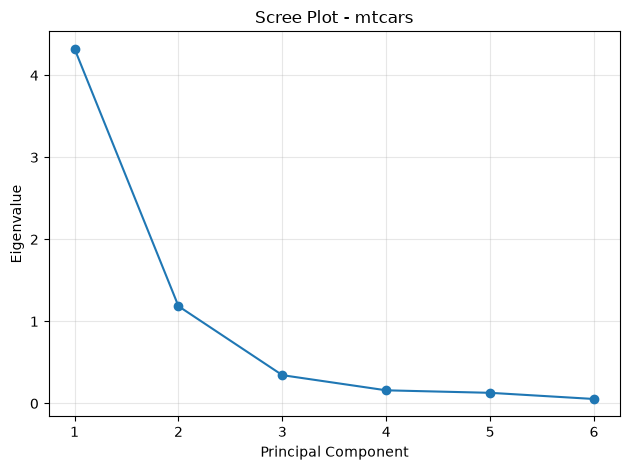


PCA LOADINGS:
         PC1     PC2     PC3     PC4     PC5     PC6
mpg  -0.4587 -0.0587 -0.1948  0.7821  0.1112  0.3525
disp  0.4660  0.0607  0.0969  0.6000 -0.2946 -0.5683
hp    0.4259 -0.3615  0.1461  0.1230  0.8057  0.0477
drat -0.3671 -0.4365  0.8005  0.0226 -0.1438 -0.1128
wt    0.4386  0.2995  0.4178  0.1044 -0.2302  0.6925
qsec -0.2528  0.7628  0.3406  0.0427  0.4219 -0.2415

PC1 LOADINGS (SORTED BY ABSOLUTE MAGNITUDE):
disp    0.4660
mpg    -0.4587
wt      0.4386
hp      0.4259
drat   -0.3671
qsec   -0.2528

PC2 LOADINGS (SORTED BY ABSOLUTE MAGNITUDE):
qsec    0.7628
drat   -0.4365
hp     -0.3615
wt      0.2995
disp    0.0607
mpg    -0.0587


In [3]:
plt.plot(
    range(1, len(eigenvalues) + 1),
    eigenvalues,
    marker="o"
)
plt.xticks(range(1, len(eigenvalues) + 1))
plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("Scree Plot - mtcars")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=[f"PC{i + 1}" for i in range(len(cols))]
)
print("\nPCA LOADINGS:")
print(loadings.round(4).to_string())
print("\nPC1 LOADINGS (SORTED BY ABSOLUTE MAGNITUDE):")
print(loadings["PC1"].sort_values(
    key=abs, ascending=False
).round(4).to_string())
print("\nPC2 LOADINGS (SORTED BY ABSOLUTE MAGNITUDE):")
print(loadings["PC2"].sort_values(
    key=abs, ascending=False
).round(4).to_string())

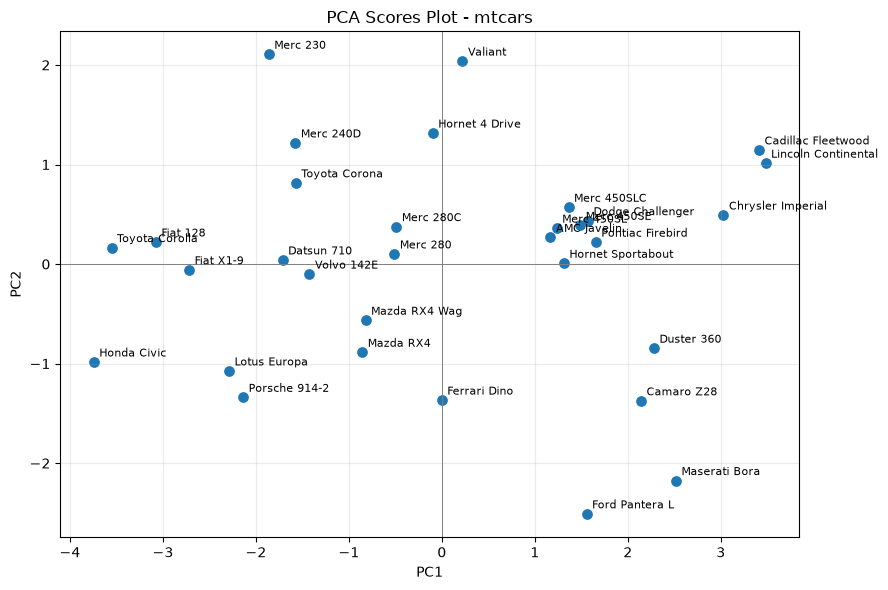

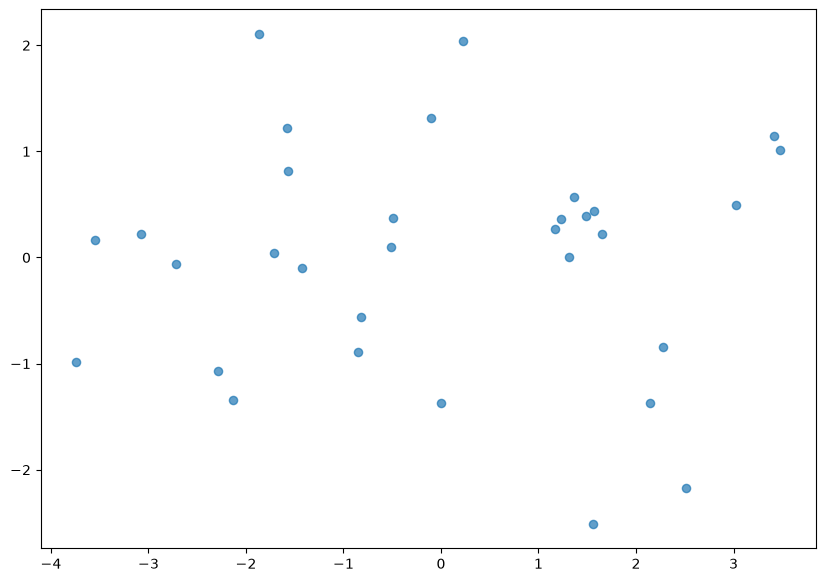

In [4]:
# PCA scores plot with observation labels
plt.figure(figsize=(9, 6))
plt.scatter(scores[:, 0], scores[:, 1], s=45)
for i, label in enumerate(data.index):
    plt.annotate(
        str(label),
        (scores[i, 0], scores[i, 1]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )
plt.axhline(0, color="grey", linewidth=0.7)
plt.axvline(0, color="grey", linewidth=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Scores Plot - mtcars")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()
# PCA biplot: observation scores and variable-loading arrows
plt.figure(figsize=(10, 7))
plt.scatter(scores[:, 0], scores[:, 1], s=35, alpha=0.7)

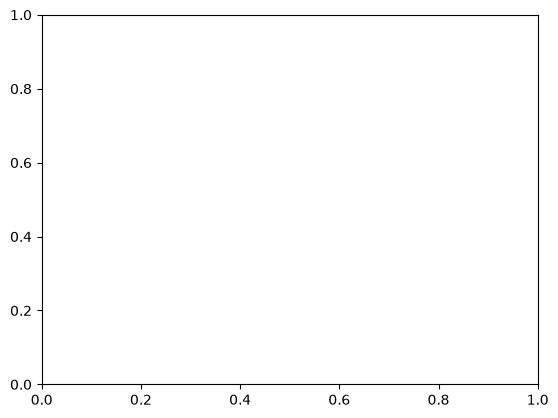

In [5]:
for i, label in enumerate(data.index):
    plt.annotate(
        str(label),
        (scores[i, 0], scores[i, 1]),
        fontsize=7,
        xytext=(3, 3),
        textcoords="offset points"
    )
# Scale arrows for readability; arrows show variable directions
arrow_scale = min(
    np.max(np.abs(scores[:, :2])) / 2,
    3
)

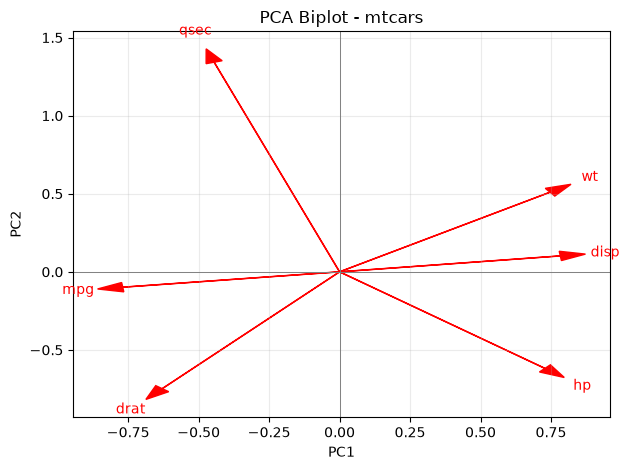

In [6]:
for i, variable in enumerate(cols):
    x_loading = pca.components_[0, i] * arrow_scale
    y_loading = pca.components_[1, i] * arrow_scale

    plt.arrow(
        0, 0,
        x_loading, y_loading,
        color="red",
        head_width=0.06,
        length_includes_head=True
    )

    plt.text(
        x_loading * 1.08,
        y_loading * 1.08,
        variable,
        color="red",
        fontsize=10,
        ha="center",
        va="center"
    )
plt.axhline(0, color="grey", linewidth=0.7)
plt.axvline(0, color="grey", linewidth=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot - mtcars")
plt.grid(True, alpha=0.25)
plt.tight_layout()